<a href="https://colab.research.google.com/github/Orliluq/amenazas_digitales/blob/main/amenazas_digitales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **🤖 Del ataque a la defensa: ¿cómo puede ayudarnos la inteligencia artificial a combatir las amenazas digitales?**


## **Detectar accesos anómalos con Machine Learning**
En nuestro ejemplo, simularemos un escenario empresarial en el que queremos detectar posibles comportamientos sospechosos en los registros de autenticación.

## **¿Qué vamos a analizar?**

Cada registro representará una ventana de actividad de acceso y contendrá estas variables:

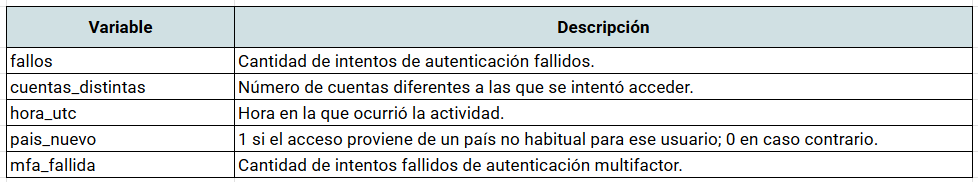

## **Paso 1. Instalar las dependencias**

In [9]:
pip install pandas scikit-learn

## **Paso 2. Preparar los datos**

Necesitamos dos archivos CSV:

- `accesos_normales.csv`: contiene registros históricos revisados y representativos de actividad legítima.

- `accesos_recientes.csv`: contiene los registros que queremos analizar.

In [10]:
%%writefile accesos_recientes.csv
fallos,cuentas_distintas,hora_utc,pais_nuevo,mfa_fallida
0,1,10,0,0
1,1,11,0,0
0,1,14,0,0
2,1,9,0,0

Overwriting accesos_recientes.csv


In [11]:
%%writefile accesos_normales.csv
fallos,cuentas_distintas,hora_utc,pais_nuevo,mfa_fallida
0,1,12,0,0
0,1,13,0,0
1,1,15,0,0
0,1,16,0,0
0,1,9,0,0
0,2,14,0,0
1,1,10,0,0
0,1,17,0,0
0,1,8,0,0
0,1,22,0,0

Overwriting accesos_normales.csv


## **Paso 3. Construir nuestro detector de anomalías**

In [12]:
import pandas as pd

from sklearn.ensemble import IsolationForest

# Variables que analizará el modelo
FEATURES = [
    "fallos",
    "cuentas_distintas",
    "hora_utc",
    "pais_nuevo",
    "mfa_fallida"
]

# Cargar los datos
historial = pd.read_csv("accesos_normales.csv")
recientes = pd.read_csv("accesos_recientes.csv")

# Validar las columnas requeridas
for nombre, datos in [
    ("historial", historial),
    ("recientes", recientes)
]:
    faltantes = set(FEATURES) - set(datos.columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas en {nombre}: {faltantes}"
        )

    if datos[FEATURES].isna().any().any():
        raise ValueError(
            f"Hay valores vacíos en {nombre}"
        )

# Crear el modelo de detección
modelo = IsolationForest(
    n_estimators=200,
    contamination=0.02,
    random_state=42
)

# Entrenar con actividad histórica revisada
modelo.fit(historial[FEATURES])

# Analizar los registros recientes
predicciones = modelo.predict(recientes[FEATURES])

# -1 representa una posible anomalía
#  1 representa un comportamiento no identificado como anómalo
recientes["alerta_ia"] = predicciones == -1

# Obtener una puntuación de anomalía
recientes["score_anomalia"] = (
    modelo.decision_function(recientes[FEATURES])
)

# Mostrar los eventos que requieren revisión
alertas = recientes[
    recientes["alerta_ia"]
].sort_values("score_anomalia")

print("RESULTADO DEL ANÁLISIS")

if alertas.empty:
    print("No se detectaron anomalías con este modelo.")
else:
    print("Eventos que requieren revisión:")

    print(
        alertas[
            FEATURES + ["score_anomalia"]
        ].to_string(index=False)
    )

RESULTADO DEL ANÁLISIS
No se detectaron anomalías con este modelo.


## **Paso 4. ¿Qué está haciendo realmente el modelo?**

*Isolation Forest* utiliza árboles de aislamiento para separar observaciones que se comportan de manera diferente al resto.

En términos sencillos, intenta identificar qué registros son más fáciles de aislar por presentar características poco habituales.

El resultado es una clasificación:
- 1: el registro no ha sido identificado como anomalía.
- -1: el registro ha sido identificado como posible anomalía.

También obtenemos `score_anomalia`, una puntuación que permite ordenar los eventos según su grado de aislamiento. Los valores más bajos indican observaciones más atípicas.

**Importante:** una anomalía no equivale necesariamente a un ataque. Un empleado que viaja, un cambio de horario o una nueva ubicación de trabajo pueden generar alertas legítimas.

Además, el parámetro `contamination=0.02` establece una proporción esperada de anomalías para determinar el umbral de clasificación. No significa que el 2 % de los registros sean ataques confirmados.

Por eso, nuestro detector no bloquea usuarios automáticamente: genera señales para que un equipo de seguridad pueda investigarlas.

Para visualizar los resultados del modelo, empleamos un gráfico utilizando `matplotlib` y `seaborn`. El gráfico muestra la puntuación de anomalía (`score_anomalia`) de los accesos recientes.


Los valores más bajos o negativos representan comportamientos más atípicos (anomalías), mientras que los valores altos representan accesos que el modelo considera totalmente normales.

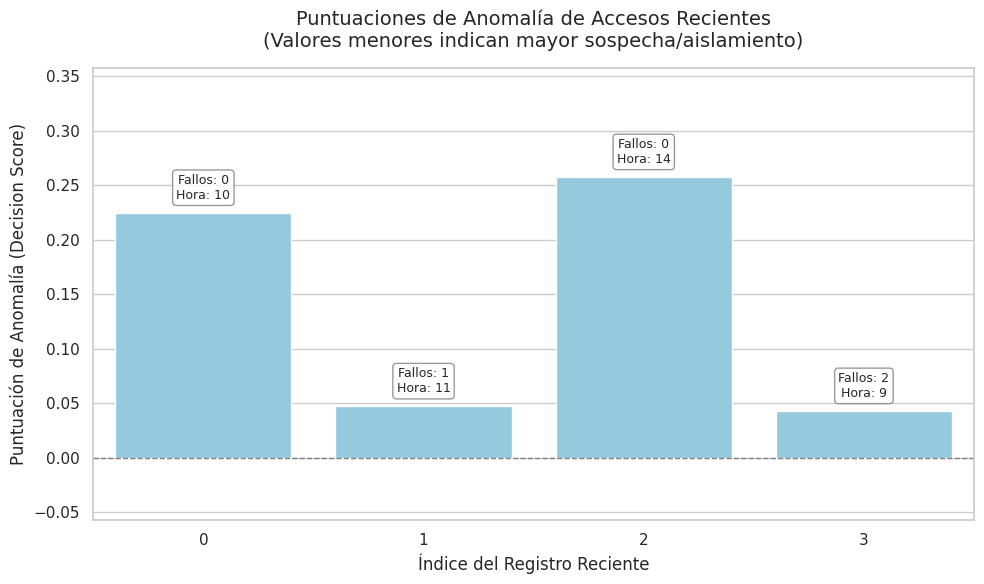

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear un gráfico de barras para visualizar las puntuaciones de anomalía de los accesos recientes
colores = ['red' if alerta else 'skyblue' for alerta in recientes['alerta_ia']]

ax = sns.barplot(
    x=recientes.index,
    y=recientes['score_anomalia'],
    palette=colores,
    hue=recientes.index,
    legend=False
)

# Añadir etiquetas con las características del acceso sobre cada barra
for i, fila in recientes.iterrows():
    etiqueta = f"Fallos: {fila['fallos']}\nHora: {fila['hora_utc']}"
    plt.text(
        i,
        fila['score_anomalia'] + 0.01 if fila['score_anomalia'] >= 0 else fila['score_anomalia'] - 0.02,
        etiqueta,
        ha='center',
        va='bottom' if fila['score_anomalia'] >= 0 else 'top',
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8)
    )

# Personalizar el gráfico
plt.title("Puntuaciones de Anomalía de Accesos Recientes\n(Valores menores indican mayor sospecha/aislamiento)", fontsize=14, pad=15)
plt.xlabel("Índice del Registro Reciente", fontsize=12)
plt.ylabel("Puntuación de Anomalía (Decision Score)", fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

# Ajustar límites y visualización
plt.ylim(min(recientes['score_anomalia']) - 0.1, max(recientes['score_anomalia']) + 0.1)
plt.tight_layout()
plt.show()

## **¿Cómo interpretar este gráfico?**
**Puntuación de Anomalía (Eje Y):** Representa qué tan "común" es el acceso según el historial de entrenamiento.

- **Valores más altos (barras más largas hacia arriba):** Representan comportamientos muy alineados con lo habitual (por ejemplo, el registro **2** con 0 fallos a las 14:00 tiene la puntuación más alta y segura).
- **Valores más bajos (cercanos a 0 o negativos):** Indican que el registro es atípico o sospechoso. Observa las barras **1** (1 fallo a las 11:00) y **3** (2 fallos a las 9:00); sus puntuaciones son notablemente más bajas, lo que demuestra que el modelo identifica que se están alejando del patrón normal.



**Color de las barras:**
Actualmente todas las barras son celestes porque ninguno de estos accesos recientes cruzó el umbral crítico para ser clasificado estrictamente como anomalía (`alerta_ia = True`).

Si el modelo hubiese detectado una anomalía confirmada (un valor menor a 0 o dentro del porcentaje de contaminación), esa barra se habría pintado automáticamente de **rojo** para llamar la atención del analista de seguridad.